# Assignment 3: Borders and Image Complements

**Objective:** Add a constant-colour border around a grayscale image, and compute the complement (negative) of both a grayscale and a binary image.

> The input image is generated in code (no external image files needed). Settings that used to be typed in with `input()` are now variables at the top of each cell, so the notebook runs top to bottom without prompts.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


def create_demo_image(size=128, seed=42):
    """Build a grayscale test image (gradient + shapes + texture) with NumPy and OpenCV."""
    rng = np.random.default_rng(seed)

    # Smooth horizontal gradient as the background
    canvas = np.tile(np.linspace(40, 140, size, dtype=np.float32), (size, 1))

    # Bright square, dark circle and a mid-grey diagonal line give us edges and flat regions
    cv2.rectangle(canvas, (size // 8, size // 8), (size // 2, size // 2), 220, -1)
    cv2.circle(canvas, (int(size * 0.70), int(size * 0.65)), size // 5, 30, -1)
    cv2.line(canvas, (0, size - 1), (size - 1, size // 3), 180, 3)

    # Light texture so the image is not perfectly smooth
    canvas += rng.normal(0, 4, canvas.shape)
    return np.clip(canvas, 0, 255).astype(np.uint8)


def show_images(images, titles, columns=None, figsize=None):
    """Display several grayscale images side by side with titles."""
    columns = columns or len(images)
    rows = int(np.ceil(len(images) / columns))
    plt.figure(figsize=figsize or (4 * columns, 4 * rows))
    for index, (picture, title) in enumerate(zip(images, titles), start=1):
        plt.subplot(rows, columns, index)
        plt.imshow(picture, cmap="gray", vmin=0, vmax=255)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## Part A: Add a border
Set the border width (pixels) and grey level (0-255).

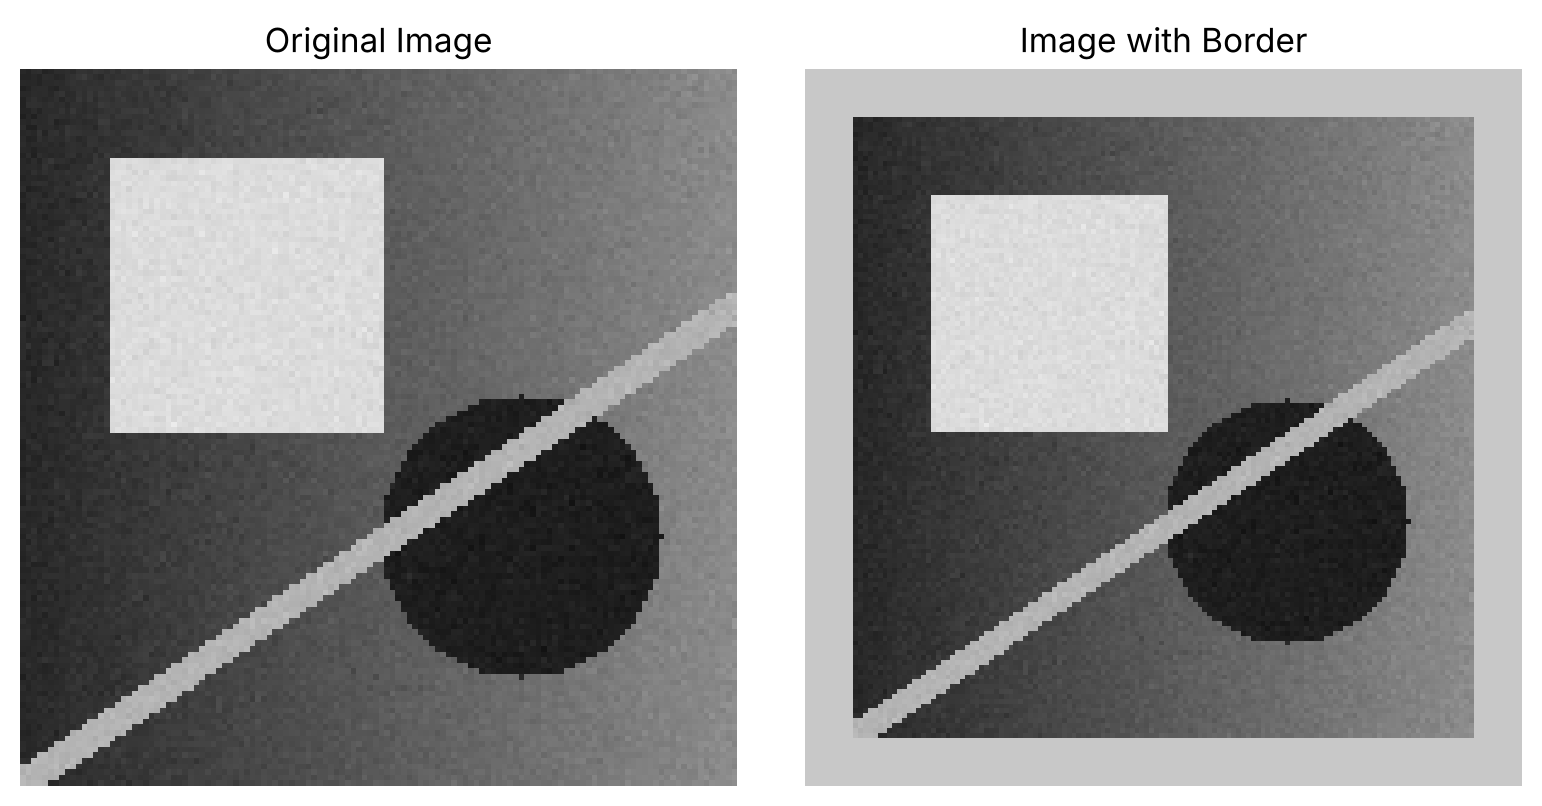

In [2]:
BORDER_WIDTH = 10    # change me
BORDER_COLOR = 200   # change me (0-255)

grayscale_image = create_demo_image()

bordered_image = cv2.copyMakeBorder(
    grayscale_image,
    BORDER_WIDTH, BORDER_WIDTH, BORDER_WIDTH, BORDER_WIDTH,
    cv2.BORDER_CONSTANT,
    value=BORDER_COLOR,
)

show_images([grayscale_image, bordered_image], ["Original Image", "Image with Border"])

## Part B: Complements
The complement of an 8-bit image is `255 - image`. A fixed threshold of 127 is used for the binary version.

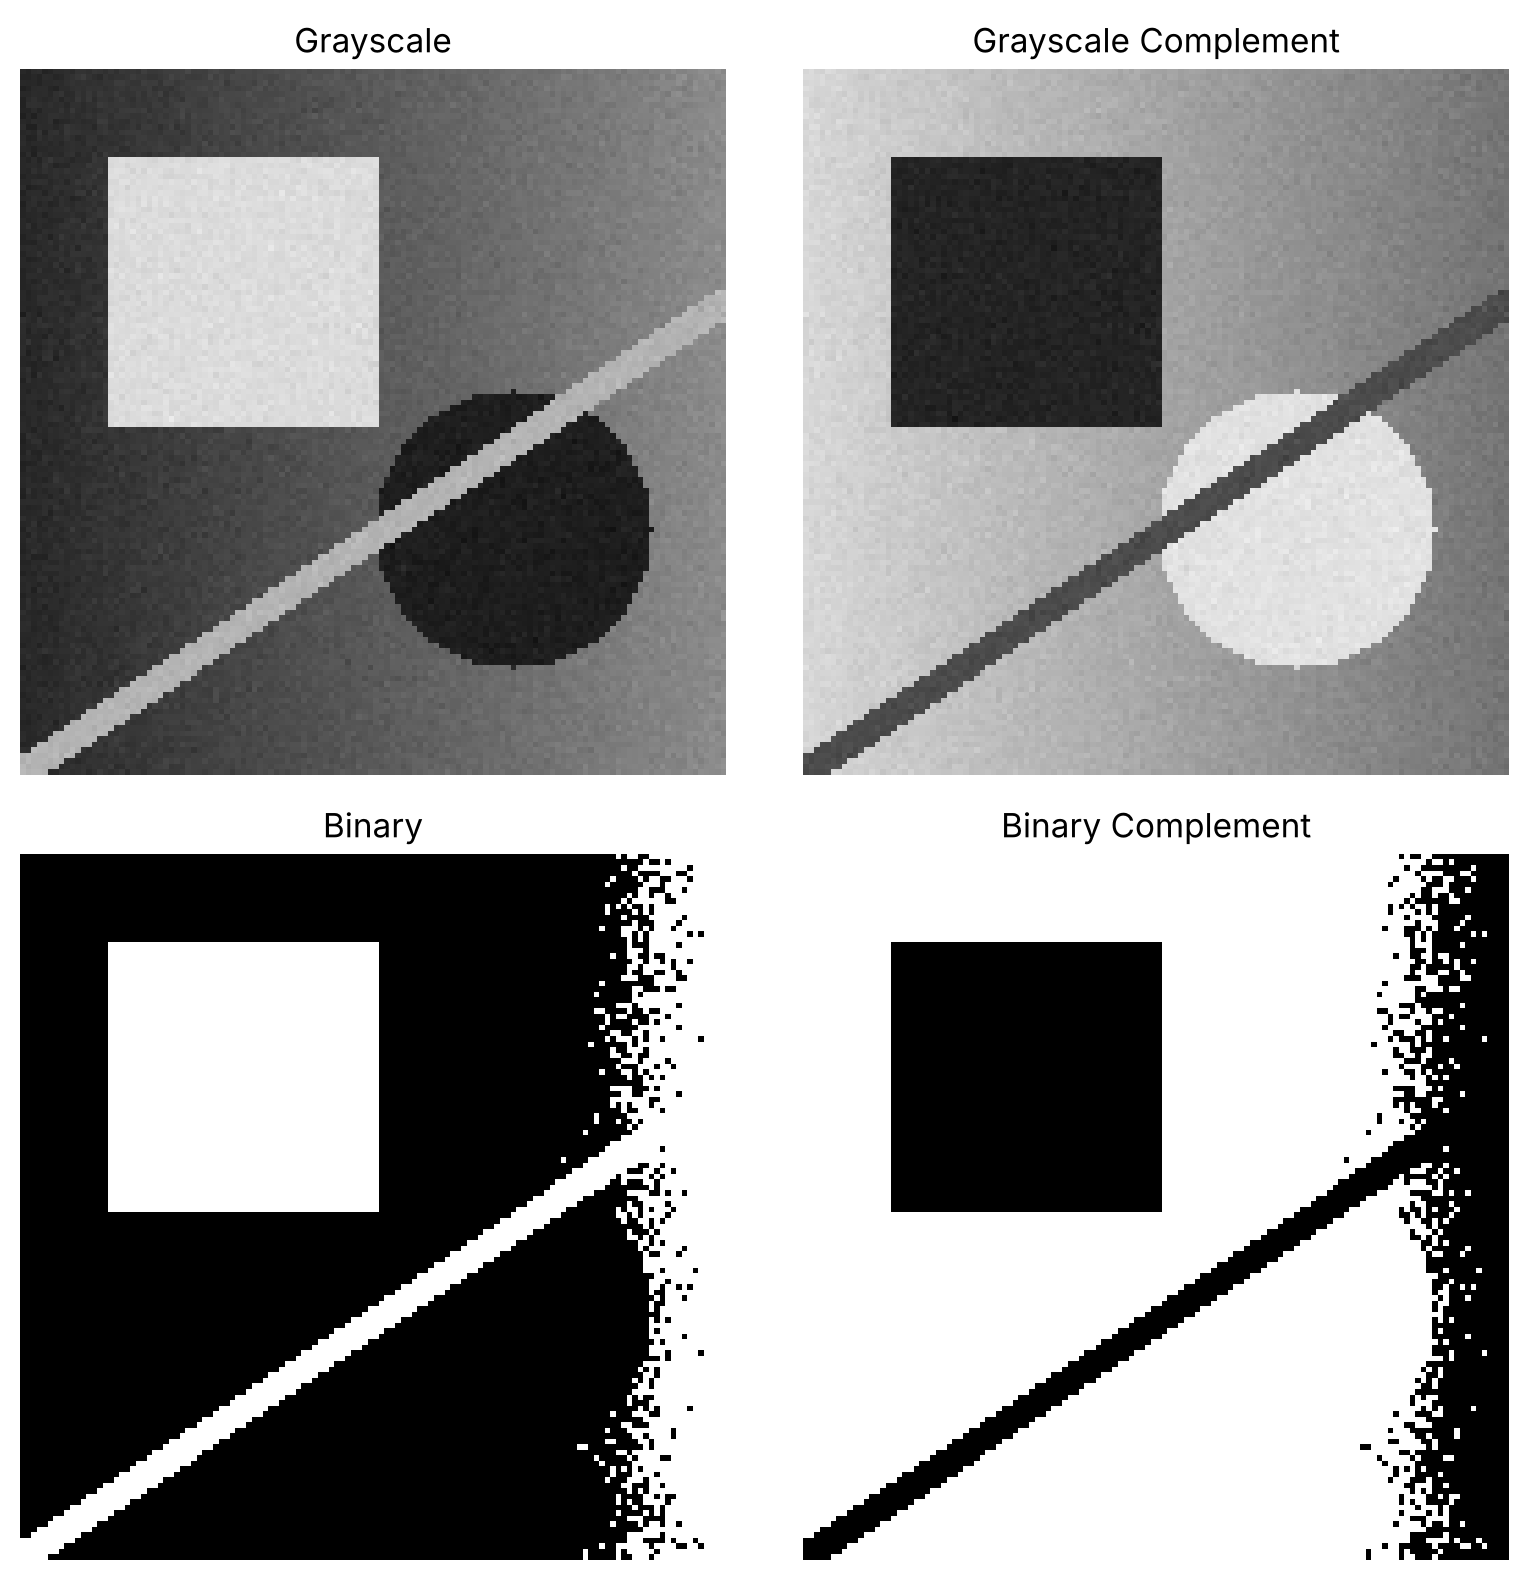

In [3]:
grayscale_image = create_demo_image()
grayscale_complement = 255 - grayscale_image

_, binary_image = cv2.threshold(grayscale_image, 127, 255, cv2.THRESH_BINARY)
binary_complement = 255 - binary_image

show_images(
    [grayscale_image, grayscale_complement, binary_image, binary_complement],
    ["Grayscale", "Grayscale Complement", "Binary", "Binary Complement"],
    columns=2, figsize=(8, 8),
)